# Loding Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Uploading dataset

In [3]:
df=pd.read_csv('cars2018.csv')

# Introducing with Data

The primary objective of this ptoject is to use the automobile dataset — encompassing attributes
 such as aspiration, fuel type, engine size, horsepower, among others — to predict the distance a vehicle is capable of traveling.
 This task is formulated as a regression problem within the broader scope of predictive modeling

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   model                    1144 non-null   object 
 1   model_index              1144 non-null   int64  
 2   displacement             1144 non-null   float64
 3   cylinders                1144 non-null   int64  
 4   gears                    1144 non-null   int64  
 5   transmission             1144 non-null   object 
 6   mpg                      1144 non-null   int64  
 7   aspiration               1144 non-null   object 
 8   lockup_torque_converter  1144 non-null   object 
 9   drive                    1144 non-null   object 
 10  max_ethanol              1144 non-null   int64  
 11  recommended_fuel         1144 non-null   object 
 12  intake_valves_per_cyl    1144 non-null   int64  
 13  exhaust_valves_per_cyl   1144 non-null   int64  
 14  fuel_injection          

In [7]:
df.head()

,model,model_index,displacement,cylinders,gears,transmission,mpg,aspiration,lockup_torque_converter,drive,max_ethanol,recommended_fuel,intake_valves_per_cyl,exhaust_valves_per_cyl,fuel_injection
0,Acura NSX,57,3.5,6,9,Manual,21,Turbocharged/Supercharged,Y,All Wheel Drive,10,Premium Unleaded Required,2,2,Direct ignition
1,ALFA ROMEO 4C,410,1.8,4,6,Manual,28,Turbocharged/Supercharged,Y,"2-Wheel Drive, Rear",10,Premium Unleaded Required,2,2,Direct ignition
2,Audi R8 AWD,65,5.2,10,7,Manual,17,Naturally Aspirated,Y,All Wheel Drive,15,Premium Unleaded Recommended,2,2,Direct ignition
3,Audi R8 RWD,71,5.2,10,7,Manual,18,Naturally Aspirated,Y,"2-Wheel Drive, Rear",15,Premium Unleaded Recommended,2,2,Direct ignition
4,Audi R8 Spyder AWD,66,5.2,10,7,Manual,17,Naturally Aspirated,Y,All Wheel Drive,15,Premium Unleaded Recommended,2,2,Direct ignition


In [6]:
df = df.drop('Unnamed: 15', axis=1)

# Data Preprocessing with class

In [ ]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
class Datapreprocessing:                 # class orqali belgilab olib jami data processingni bitta class bilan bajarmoqchimiz
    def __init__(self, df):
        self.df = df.copy()
    
    # Handle missing values
    def tozala(self):
        for col in self.df.columns:
            if self.df[col].isnull().any():
                if self.df[col].dtype == 'object':
                    self.df[col].fillna(self.df[col].mode()[0], inplace=True)
                else:
                    self.df[col].fillna(self.df[col].mean(), inplace=True)
        return self
    
    # Encode categorical variables
    def encodla(self):
        encoder = LabelEncoder()
        for col in self.df.columns:
            if self.df[col].dtype == 'object':
                if self.df[col].nunique() <= 5:  # few categories → OneHot
                    dummies = pd.get_dummies(self.df[col], prefix=col, dtype=int)
                    self.df = pd.concat([self.df.drop(columns=[col]), dummies], axis=1)
                else:  # many categories → Label Encoding
                    self.df[col] = encoder.fit_transform(self.df[col])
        return self
    
    # Scale numeric features
    def scale_qil(self):
        scaler = MinMaxScaler()
        num_cols = self.df.select_dtypes(include=['int64', 'float64']).columns.drop('mpg', errors='ignore')
        self.df[num_cols] = scaler.fit_transform(self.df[num_cols])
        return self
    
    # Log transformation for skewed features
    def log_transform(self, threshold=0.5):
        skewness = self.df.skew()
        features_log = skewness[(skewness >= threshold)].index.tolist()   # bu yerda theshold istalgan ozgaruvchi sifatida belgilab oldik qaysiki 0.5 ga teng
        
        for col in features_log:
            if (self.df[col] > 0).all():  # only positive values
                self.df[col] = np.log1p(self.df[col])
        return self


In [145]:
processor = Datapreprocessing(df)

df_ready = (
    processor
    .tozala()
    .encodla()
    .scale_qil()
    .log_transform()
    .df
)

print(df_ready.head())

      model  model_index  displacement  cylinders     gears       mpg  \
0  0.009346     0.068293      0.357143   0.230769  0.888889  0.212766   
1  0.000000     0.498780      0.114286   0.076923  0.555556  0.361702   
2  0.045394     0.078049      0.600000   0.538462  0.666667  0.127660   
3  0.046729     0.085366      0.600000   0.538462  0.666667  0.148936   
4  0.048064     0.079268      0.600000   0.538462  0.666667  0.127660   

   max_ethanol  intake_valves_per_cyl  exhaust_valves_per_cyl  \
0     0.000000                    1.0                     1.0   
1     0.000000                    1.0                     1.0   
2     0.066667                    1.0                     1.0   
3     0.066667                    1.0                     1.0   
4     0.066667                    1.0                     1.0   

   transmission_Automatic  ...  lockup_torque_converter_Y  \
0                     0.0  ...                        1.0   
1                     0.0  ...                  

In [146]:
df=df_ready

In [147]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 25 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   model                                          1144 non-null   float64
 1   model_index                                    1144 non-null   float64
 2   displacement                                   1144 non-null   float64
 3   cylinders                                      1144 non-null   float64
 4   gears                                          1144 non-null   float64
 5   mpg                                            1144 non-null   float64
 6   max_ethanol                                    1144 non-null   float64
 7   intake_valves_per_cyl                          1144 non-null   float64
 8   exhaust_valves_per_cyl                         1144 non-null   float64
 9   transmission_Automatic                         1144 

In [148]:
df.head()

,model,model_index,displacement,cylinders,gears,mpg,max_ethanol,intake_valves_per_cyl,exhaust_valves_per_cyl,transmission_Automatic,...,lockup_torque_converter_Y,"drive_2-Wheel Drive, Front","drive_2-Wheel Drive, Rear",drive_4-Wheel Drive,drive_All Wheel Drive,recommended_fuel_Premium Unleaded Recommended,recommended_fuel_Premium Unleaded Required,recommended_fuel_Regular Unleaded Recommended,fuel_injection_Direct ignition,fuel_injection_Multipoint/sequential ignition
0,0.009346,0.068293,0.357143,0.230769,0.888889,0.212766,0.000000,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.000000,0.498780,0.114286,0.076923,0.555556,0.361702,0.000000,1.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.045394,0.078049,0.600000,0.538462,0.666667,0.127660,0.066667,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
3,0.046729,0.085366,0.600000,0.538462,0.666667,0.148936,0.066667,1.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.048064,0.079268,0.600000,0.538462,0.666667,0.127660,0.066667,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


# Saving Preprocessed Data

In [14]:
import os

In [149]:
output_folder='data/preprocessed'
os.makedirs(output_folder,exist_ok=True)
output_path=os.path.join(output_folder,'preprocessed_data.csv')
df.to_csv(output_path,index=False)
print(f"Preprocessed dataset saved to : {output_path}")

Preprocessed dataset saved to : data/preprocessed\preprocessed_data.csv


# Feature Transformation

# Filter Methods

In [ ]:
# Correlation _high variance features

corr_matrix = df.corr().abs()   # muhim bolgan featurelarni topib olish codimiz va yana musbat bolganlarini oladi
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)) # yuqori ahamiyatli featurelarni aniqlab olish
to_drop = [col for col in upper.columns if any(upper[col] > 0.8)]     # yani 80% dan yuqori ahamiyatlilarini tashlashga buyruq beryapmiz
df_filtered = df.drop(columns=to_drop)   # alohida nom bilan belgilab olisholib high variance qiymatlarni tashlab yubordik
print("\nOriginal shape:", df.shape)
print("Shape after dropping correlated features:", df_filtered.shape)  # Demak, ba’zi ustunlar korrelyatsiya sababli o‘chirildi va endi 18 ustun qoldi.


Original shape: (1144, 25)
Shape after dropping correlated features: (1144, 18)


In [167]:
df_filtered.info()  #ahamiyatliligi jihatdan saralangan featurelar

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 18 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   model                                          1144 non-null   float64
 1   model_index                                    1144 non-null   float64
 2   displacement                                   1144 non-null   float64
 3   gears                                          1144 non-null   float64
 4   mpg                                            1144 non-null   float64
 5   max_ethanol                                    1144 non-null   float64
 6   intake_valves_per_cyl                          1144 non-null   float64
 7   transmission_Automatic                         1144 non-null   float64
 8   transmission_CVT                               1144 non-null   float64
 9   aspiration_Naturally Aspirated                 1144 

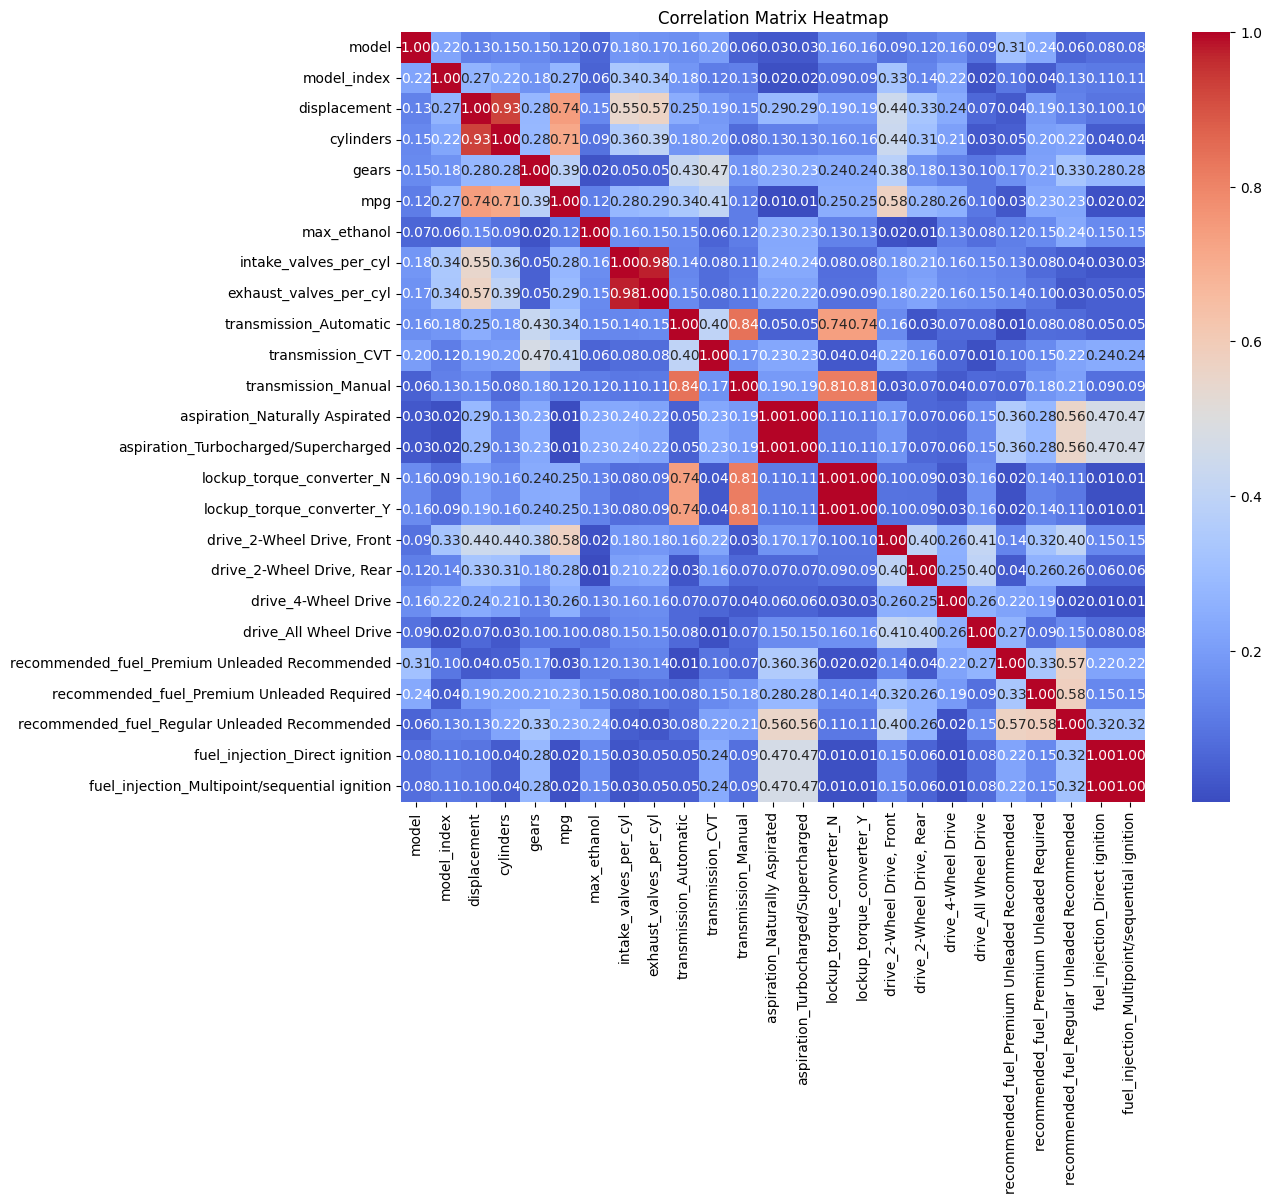

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix Heatmap")  # pifagor jadval orqali har bitta inputlarimizni hohlagan bitta boshqa input yoki otput bilan ahamiyatliligi darajasini korsatuvchi heatmap
plt.show()

In [169]:
#Low Vairance
from sklearn.feature_selection import VarianceThreshold

# Set threshold for variance (e.g., 0.01)
threshold = 0.01                               #  bu ozgaruvchi eng kam qiymat 0.01 bolsin deb belgilab oldik

# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=threshold)

# Fit on the dataset
selector.fit(df_filtered)                 # fit transform qildik

# Features with low variance
low_variance_features = df_filtered.columns[~selector.get_support()]  # threshold qiymatga kora low variance qiymatlarni  support yordamida saralab oldik
print("Features with low variance (to drop):", list(low_variance_features))

# Drop low-variance features                    # bu codda esa osha saralab olingan lowa variance qiymatlarni tashlab yubordik
df_low_variance_filtered = df_filtered.drop(columns=low_variance_features)
print("\nOriginal shape:", df_filtered.shape)
print("Shape after dropping low-variance features:", df_low_variance_filtered.shape)  # Demak threshold belgilangan qiymat boyicha hech qanday low variance qiymatlar topilmadi va tashlaab yuborilmadi

Features with low variance (to drop): []

Original shape: (1144, 18)
Shape after dropping low-variance features: (1144, 18)


# Model Training Process

In [40]:
# separating input and output features,respectively  x and y. 
from sklearn.model_selection import train_test_split

In [41]:
x=df.drop('mpg',axis=1)

In [42]:
y=df['mpg']

In [43]:
# The dataset is divided into two separate parts: a training  and a testing 
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

# Model Selection

In [104]:
# Import algorithms

from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.svm import SVC,SVR
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.model_selection import  KFold, cross_val_score

In [54]:
# Import metrics

from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error,r2_score,mean_absolute_error,mean_squared_error

# Linear Regression

In [109]:
lr=LinearRegression()

lr.fit(x_train,y_train)



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [110]:

y_pred = lr_model.predict(x_test)

In [111]:
lr_r2=r2_score(y_test,y_pred)
lr_mae=mean_absolute_error(y_test,y_pred)

In [112]:
print(lr_r2)
print(lr_mae)

0.723902577241358
0.040550053885574075


# Decision Tree Regression

In [133]:
dtr=DecisionTreeRegressor()

In [134]:
dtr

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [135]:
# fit_Traing_process
dtr.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [136]:
#predict_process
y_pred=dtr.predict(x_test)

In [137]:
dtr_r2=r2_score(y_test,y_pred)
dtr_mae=mean_absolute_error(y_test,y_pred)

In [138]:
print(dtr_r2)
print(dtr_mae)

0.797953628325354
0.027687447737619626


# Random Forest Regressor

In [71]:
rf = RandomForestRegressor(random_state=42)

In [72]:
# fit_Traing_process
rf.fit(x_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [87]:
#predict_process

y_pred = rf.predict(x_test)

In [75]:
rf_r2=r2_score(y_test,y_pred)
rf_mae=mean_absolute_error(y_test,y_pred)

In [77]:
print(rf_r2)
print(rf_mae)

0.8889032696684368
0.02657716250116139


# Super Vector Regressor

In [85]:
svr=SVR(kernel='linear',C=1.0)

In [86]:
# fit_Traing_process

svr.fit(x_train,y_train)

,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [88]:
#predict_process

y_pred=svr.predict(x_test)

In [89]:
y_pred

array([ 0.35501402,  0.45287372,  0.30902578,  0.15597317,  0.36559131,
        0.41785534,  0.39491679,  0.24606858,  0.25178541,  0.2047166 ,
        0.29740042,  0.56897746,  0.28992192,  0.23415737,  0.45845762,
        0.44115399,  0.24673106,  0.24781294,  0.25749838,  0.42369081,
        0.32507487,  0.20163844,  0.10066837,  0.21327342,  0.39834636,
        0.2160942 ,  0.35930705,  0.23445642,  0.26821833,  0.14697224,
        0.43254243,  0.35458031,  0.20778538,  0.25057109,  0.27608533,
        0.21169103,  0.42688872,  0.26250339,  0.29622722,  0.03214024,
        0.3003193 ,  0.31510812,  0.11823654,  0.24946065,  0.35942714,
        0.2611733 ,  0.28320148,  0.23020509,  0.26683506,  0.36205347,
        0.33607452,  0.10458471,  0.21907653,  0.11840639,  0.20016342,
        0.19639863,  0.14239762, -0.03404404,  0.42141887,  0.47610669,
        0.28856985,  0.25152756,  0.13930925,  0.26720387,  0.09693783,
        0.33458358,  0.13788482,  0.21768239,  0.26956449,  0.09

In [91]:

svr_r2=r2_score(y_test,y_pred)
svr_mae=mean_absolute_error(y_test,y_pred)

In [93]:
print(svr_r2)
print(svr_mae)

0.6819494565651121
0.04659099758821674


# KNN

In [95]:
knn=KNeighborsRegressor(n_neighbors=3)

In [100]:
# fit_Traing_process

knn.fit(x_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [99]:
#predict_process

y_pred=knn.predict(x_test)

In [101]:
knn_r2=r2_score(y_test,y_pred)
knn_mae=mean_absolute_error(y_test,y_pred)

In [103]:
print(knn_r2)
print(knn_mae)

0.7133945615671707
0.04227445879401654


# K_Fold cross validation

In [105]:
kf=KFold(n_splits=5,shuffle=True,random_state=42)

In [106]:
kf

KFold(n_splits=5, random_state=42, shuffle=True)

In [113]:
scores=cross_val_score(lr,x,y,cv=kf,scoring='r2')

In [114]:
print(scores)

[0.72390258 0.64482422 0.76359467 0.7905026  0.71128401]


In [115]:
for i in scores:
    print(i)

0.7239025772413579
0.6448242218987181
0.7635946687261861
0.79050260336259
0.7112840101494566


In [116]:
np.mean(scores)

np.float64(0.7268216162756618)

In [ ]:
np.std(scores) # eski usuldagi validating va K_Fold_cross validating ortasidagi farq 0.049 juda kichik demak model yaxshi ishlayabdi ,ya'ni algoritm togri ishlayabdi

np.float64(0.049761503555498486)

In [119]:
# mae boyicha cross validation
from sklearn.metrics import make_scorer

In [120]:
mae=make_scorer(mean_absolute_error,greater_is_better=False)

In [121]:
scores=cross_val_score(lr,x,y,cv=kf,scoring=mae)

In [122]:
print(-scores)

[0.04055005 0.0469789  0.04080592 0.03858336 0.04300666]


In [124]:
print(-scores.mean())   

0.04198497878794242


# Comparing Table

In [125]:
from tabulate import tabulate

In [154]:
result = [
    ['Linear Regression', lr_r2, lr_mae],
    ['Decision Tree Regressor', dtr_r2, dtr_mae],
    ['Random Forest Regressor', rf_r2, rf_mae],
    ['SVR', svr_r2, svr_mae],
    ['KNN', knn_r2, knn_mae],
]

headers = ['Algorithm', 'r2_score', 'mean absolute error']

table = tabulate(result, headers=headers, tablefmt='grid', floatfmt='.2f')

In [155]:
print(table)

+-------------------------+------------+-----------------------+
| Algorithm               |   r2_score |   mean absolute error |
+=========================+============+=======================+
| Linear Regression       |       0.72 |                  0.04 |
+-------------------------+------------+-----------------------+
| Decision Tree Regressor |       0.80 |                  0.03 |
+-------------------------+------------+-----------------------+
| Random Forest Regressor |       0.89 |                  0.03 |
+-------------------------+------------+-----------------------+
| SVR                     |       0.68 |                  0.05 |
+-------------------------+------------+-----------------------+
| KNN                     |       0.71 |                  0.04 |
+-------------------------+------------+-----------------------+


# Comparing Algorithms in visualization

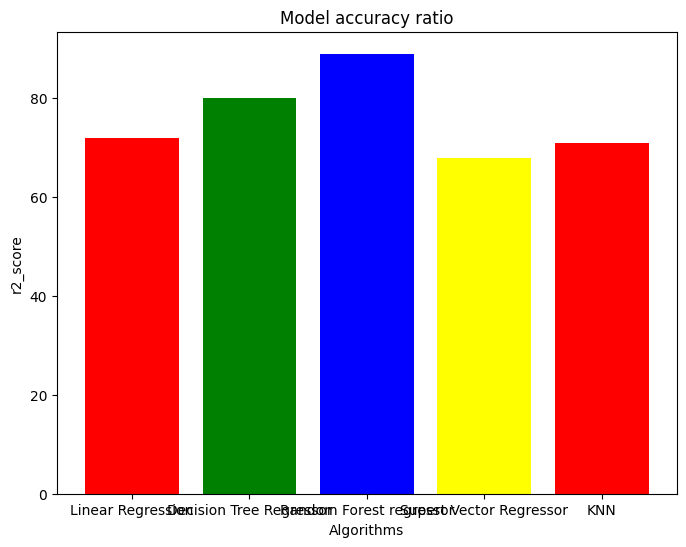

In [171]:
algorithm = ['Linear Regression','Decision Tree Regressor','Random Forest regressor','Supert Vector Regressor','KNN'] 
value = [72,80,89,68,71]
plt.figure(figsize=(8,6))
plt.bar(algorithm,value,color=['red','green','blue','yellow'])
plt.title('Model accuracy ratio')
plt.xlabel('Algorithms')
plt.ylabel('r2_score')
plt.show()

# Conclusion

Among all tested algorithms (Linear  Regression, Decision Tree Regressor, Random Forest Regressor , SVR , KNN), **Random Forest Regressor**  showed the best performance.  
This model will be selected as the final model for predictions.

# Saving the best result

In [130]:
from joblib import dump

In [157]:
dump(rf,'Predict(mpg)')

['Predict(mpg)']

In [158]:
with open("table.csv", "w", encoding="utf-8") as f:
    f.write(table)